# Olist E-commerce: Customer Retention & Delivery Experience Analysis

**Business question:** *Why don't customers come back, and how much does late delivery hurt the business?*

**Data:** [Olist Brazilian E-commerce public dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): ~99k orders (Sep-2016 to Oct-2018) across 9 relational tables, loaded into a SQLite database.

**Approach**
1. **SQL** (`sql/` folder): schema, data-quality audit, cleaned views, KPIs, cohort retention, RFM segmentation, delivery and seller analysis.
2. **Python** (this notebook): cross-checks the SQL results in pandas, visualises them, runs statistical tests, reads the results of the robustness check (`scripts/robustness_check.py`) and sizes the business impact.
3. **Dashboard** (`dashboard/` folder): interactive HTML dashboard + Power BI build guide.

**Contents:** 1. Setup · 2. Data quality · 3. Business overview · 4. Customer retention · 5. RFM segments · 6. Delivery & reviews · 7. Sellers & categories · 8. What-if impact · 9. Insights & recommendations

> Run `python run_pipeline.py` from the project root first. It builds `database/olist.db`, which this notebook reads.

## 1. Setup

In [1]:
import math
import sqlite3
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "database" / "olist.db"
SQL_RESULTS = ROOT / "outputs" / "sql_results"
FIGURES = ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
TREND_START, TREND_END = "2017-01", "2018-08"   # full months only

conn = sqlite3.connect(DB_PATH)

def q(sql):
    """Run a SQL query against the project database and return a DataFrame."""
    return pd.read_sql_query(sql, conn)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

# Chart style: light surface, hairline grid, thin marks, few colours
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK2,
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def subtitle(ax, text):
    ax.text(0, 1.02, text, transform=ax.transAxes, color=INK2, fontsize=10, va="bottom")

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")
    plt.show()

def two_prop_ztest(x1, n1, x2, n2):
    """Two-proportion z-test. Returns (p1, p2, z, two-sided p-value)."""
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    se = math.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    return p1, p2, z, math.erfc(abs(z) / math.sqrt(2))

In [2]:
# The cleaned views are defined in sql/03_clean_views.sql
orders = q("SELECT * FROM v_orders")          # one row per valid order
customers = q("SELECT * FROM v_customers")    # one row per real customer
rfm = q("SELECT * FROM rfm_customers")        # built in sql/06_rfm_segmentation.sql
delivered = orders[orders.is_delivered == 1].copy()

print(f"valid orders (excl. canceled/unavailable): {len(orders):,}")
print(f"delivered orders:                          {len(delivered):,}")
print(f"unique customers:                          {len(customers):,}")
print(f"purchase dates:                            {orders.purchase_date.min()} to {orders.purchase_date.max()}")
orders.head(3)

valid orders (excl. canceled/unavailable): 98,207
delivered orders:                          96,470
unique customers:                          94,990
purchase dates:                            2016-09-04 to 2018-09-03


,order_id,customer_unique_id,customer_city,customer_state,order_status,purchase_ts,purchase_date,purchase_month,delivered_date,estimated_date,n_items,n_sellers,product_value,freight_value,order_value,payment_type,payment_installments,review_score,is_delivered,delivery_days,delay_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,delivered,2017-10-02 10:56:33,2017-10-02,2017-10,2017-10-10,2017-10-18,1.00,1.00,29.99,8.72,38.71,voucher,1.00,4.00,1,8.40,-8.00,0.00
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,barreiras,BA,delivered,2018-07-24 20:41:37,2018-07-24,2018-07,2018-08-07,2018-08-13,1.00,1.00,118.70,22.76,141.46,boleto,1.00,4.00,1,13.80,-6.00,0.00
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,delivered,2018-08-08 08:38:49,2018-08-08,2018-08,2018-08-17,2018-09-04,1.00,1.00,159.90,19.22,179.12,credit_card,3.00,5.00,1,9.40,-18.00,0.00


## 2. Data quality: what the audit found

The full audit is in `sql/02_data_quality.sql`. Every issue below was handled before any metric was calculated:

| Issue | Size | How it was handled |
|---|---|---|
| `customer_id` is created per order, not per person | 2,997 people have more than one `customer_id` | All customer metrics use `customer_unique_id` |
| Orders with more than one review | 547 orders (814 duplicate `review_id`s) | Kept the most recent review per order |
| Canceled / unavailable orders | 1,234 orders (1.2%) | Excluded from revenue, customer and delivery metrics |
| "Delivered" orders with no delivery date | 8 | Excluded from delivery analysis |
| Carrier pickup recorded before purchase | 166 orders | Delivery time measured purchase → customer, so not affected |
| Customers whose 2+ orders were all placed on the same day | 823 customers | Repeat customer = bought on **2+ different days** (same-day orders are one basket split by seller) |
| Products without a category | 610 products | Labelled `unknown` |
| Thin first and last months | Sep–Dec 2016, Sep–Oct 2018 | Monthly trends use Jan-2017 to Aug-2018 only |
| Duplicate geolocation rows | 261,831 rows | Not needed: geography is analysed at state level |

In [3]:
pd.read_csv(SQL_RESULTS / "02_data_quality__integrity_checks.csv")

,check_name,affected
0,customers: person with >1 customer_id (repeat ...,2997
1,reviews: duplicate review_id,814
2,reviews: orders with more than one review,547
3,orders: no review at all,768
4,orders: no items,775
5,orders: no payment,1
6,order_items: product not in products table,0
7,products: missing category,610
8,products: category without English translation,2
9,orders: delivered before purchase (impossible),0


## 3. Business overview

In [4]:
kpis = pd.Series({
    "Revenue (R$)": orders.order_value.sum(),
    "Orders": len(orders),
    "Customers": orders.customer_unique_id.nunique(),
    "Average order value (R$)": orders.order_value.mean(),
    "Average items per order": orders.n_items.mean(),
    "Average review score (1-5)": orders.review_score.mean(),
}).to_frame("value")
kpis

,value
Revenue (R$),"15,735,527.03"
Orders,"98,207.00"
Customers,"94,990.00"
Average order value (R$),160.24
Average items per order,1.14
Average review score (1-5),4.12


Jan-Aug revenue: 2017 R$3.57M -> 2018 R$8.59M (+140%); orders +137%
Monthly average order value stayed between R$147 and R$174
2018 monthly revenue range: R$0.98M - R$1.16M


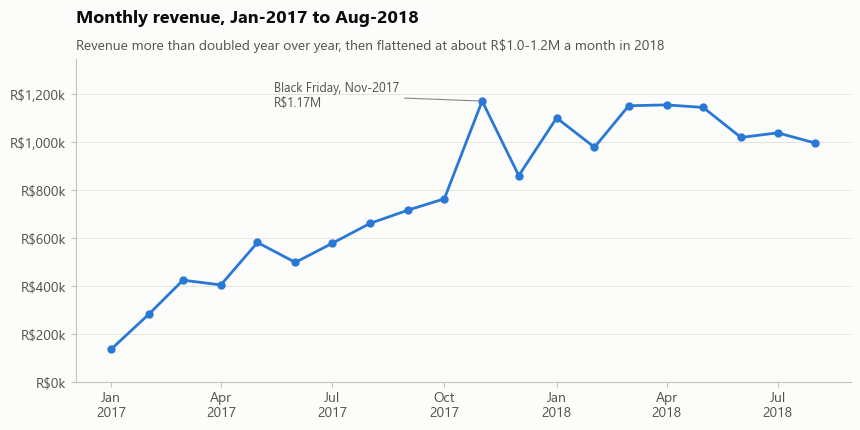

In [5]:
trend = orders[orders.purchase_month.between(TREND_START, TREND_END)]
monthly = (trend.groupby("purchase_month")
                .agg(orders=("order_id", "count"), revenue=("order_value", "sum"), aov=("order_value", "mean"))
                .reset_index())
monthly["month"] = pd.to_datetime(monthly.purchase_month + "-01")

jan_aug = trend[trend.purchase_month.str[5:7] <= "08"]
yoy = jan_aug.groupby(jan_aug.purchase_month.str[:4]).order_value.agg(["count", "sum"])
print(f"Jan-Aug revenue: 2017 R${yoy.loc['2017', 'sum'] / 1e6:.2f}M -> 2018 R${yoy.loc['2018', 'sum'] / 1e6:.2f}M "
      f"({yoy.loc['2018', 'sum'] / yoy.loc['2017', 'sum'] - 1:+.0%}); "
      f"orders {yoy.loc['2018', 'count'] / yoy.loc['2017', 'count'] - 1:+.0%}")
print(f"Monthly average order value stayed between R${monthly.aov.min():.0f} and R${monthly.aov.max():.0f}")
rev_2018 = monthly[monthly.purchase_month >= "2018-01"].revenue
print(f"2018 monthly revenue range: R${rev_2018.min() / 1e6:.2f}M - R${rev_2018.max() / 1e6:.2f}M")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly.month, monthly.revenue / 1e3, color=BLUE, marker="o", markersize=5)
peak = monthly.loc[monthly.revenue.idxmax()]
ax.annotate(f"Black Friday, Nov-2017\nR${peak.revenue / 1e6:.2f}M", xy=(peak.month, peak.revenue / 1e3),
            xytext=(-150, 4), textcoords="offset points", color=INK2, fontsize=9, va="center",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_ylim(0, monthly.revenue.max() / 1e3 * 1.15)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"R${v:,.0f}k"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.grid(axis="x", visible=False)
ax.set_title("Monthly revenue, Jan-2017 to Aug-2018", pad=26)
subtitle(ax, "Revenue more than doubled year over year, then flattened at about R$1.0-1.2M a month in 2018")
save(fig, "01_monthly_revenue")

**Takeaway:** growth came from **more orders, not bigger baskets**. Jan-Aug revenue rose 140% year over year while the average order value stayed in a narrow band. In 2018 revenue stopped growing (about R$1.0–1.2M every month). When new-customer growth flattens, **getting existing customers to buy again** is the next lever. The next section looks at that.

## 4. Customer retention

In [6]:
freq = customers.n_purchase_days.clip(upper=4).value_counts().sort_index()
freq.index = ["1", "2", "3", "4+"]
repeaters = customers[customers.n_purchase_days >= 2]
one_timers = customers[customers.n_purchase_days == 1]

print(f"one-time customers : {len(one_timers) / len(customers):.1%}")
print(f"repeat customers   : {len(repeaters):,} ({len(repeaters) / len(customers):.2%})")
print(f"avg lifetime spend : repeat R${repeaters.total_spend.mean():.0f} vs one-time R${one_timers.total_spend.mean():.0f} "
      f"({repeaters.total_spend.mean() / one_timers.total_spend.mean():.1f}x)")
pd.DataFrame({"customers": freq, "pct_of_customers": freq / freq.sum() * 100}).rename_axis("purchase_days")

one-time customers : 97.8%
repeat customers   : 2,065 (2.17%)
avg lifetime spend : repeat R$321 vs one-time R$162 (2.0x)


,customers,pct_of_customers
purchase_days,,
1,92925,97.83
2,1909,2.01
3,124,0.13
4+,32,0.03


In [7]:
# How long until the second purchase?
days = orders[["customer_unique_id", "purchase_date"]].drop_duplicates()
days = days.assign(purchase_date=pd.to_datetime(days.purchase_date)).sort_values(["customer_unique_id", "purchase_date"])
days["nth"] = days.groupby("customer_unique_id").cumcount() + 1
first_two = days[days.nth <= 2].pivot(index="customer_unique_id", columns="nth", values="purchase_date").dropna()
gap_days = (first_two[2] - first_two[1]).dt.days

print(f"median days to 2nd purchase: {gap_days.median():.0f}")
print(f"2nd purchase within 30 days: {(gap_days <= 30).mean():.0%} | within 90 days: {(gap_days <= 90).mean():.0%}")

median days to 2nd purchase: 74
2nd purchase within 30 days: 30% | within 90 days: 55%


In [8]:
# Cohort retention in pandas, then cross-checked against the SQL version
def month_index(s):
    return s.str[:4].astype(int) * 12 + s.str[5:7].astype(int)

first_month = orders.groupby("customer_unique_id").purchase_month.min().rename("cohort_month")
activity = orders[["customer_unique_id", "purchase_month"]].drop_duplicates().join(first_month, on="customer_unique_id")
activity["month_number"] = month_index(activity.purchase_month) - month_index(activity.cohort_month)

in_window = activity.cohort_month.between(TREND_START, TREND_END) & (activity.month_number <= 12)
counts = activity[in_window].groupby(["cohort_month", "month_number"]).size().unstack().fillna(0)
retention = counts.div(counts[0], axis=0) * 100

# Months after Aug-2018 cannot be observed yet: blank instead of 0
last_month = month_index(pd.Series([TREND_END])).iloc[0]
cohort_idx = month_index(pd.Series(retention.index, index=retention.index))
for m in retention.columns:
    retention.loc[cohort_idx + m > last_month, m] = np.nan

sql_cohort = pd.read_csv(SQL_RESULTS / "05_customer_retention__cohort_retention.csv")
sql_values = sql_cohort.set_index(["cohort_month", "month_number"]).retention_pct
pandas_values = retention.stack().reindex(sql_values.index)
print(f"max difference vs SQL cohort table: {(sql_values - pandas_values).abs().max():.3f} percentage points")

observed = retention[1].notna()
month1 = counts.loc[observed, 1].sum() / counts.loc[observed, 0].sum() * 100
print(f"customers buying again in the month after their first purchase: {month1:.2f}%")

max difference vs SQL cohort table: 0.005 percentage points
customers buying again in the month after their first purchase: 0.48%


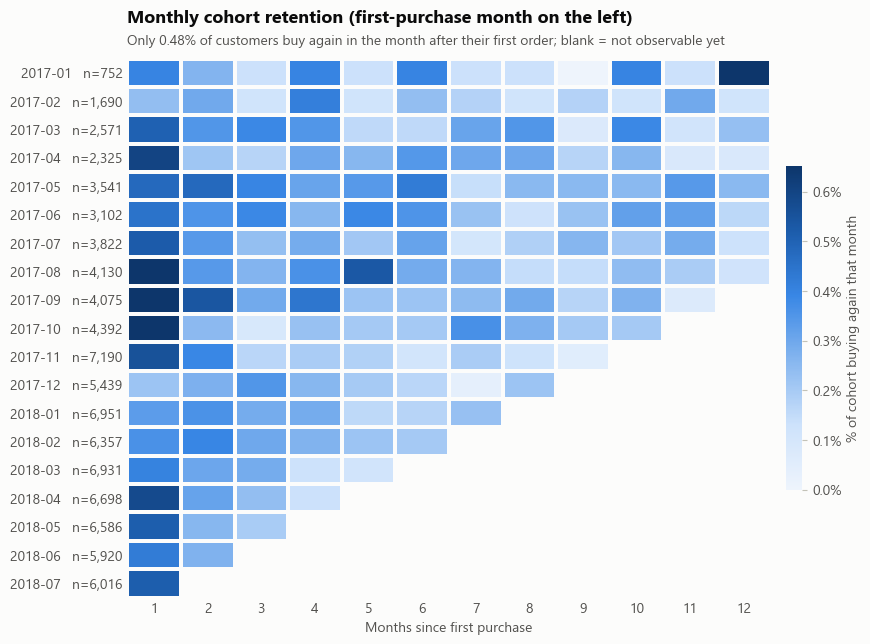

In [9]:
heat = retention.drop(columns=0).dropna(how="all")   # Aug-2018 cohort has no observable month yet
sizes = counts[0].astype(int)
cmap = LinearSegmentedColormap.from_list(
    "seq_blue", ["#eef4fc", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

fig, ax = plt.subplots(figsize=(10, 7))
mesh = ax.pcolormesh(np.ma.masked_invalid(heat.values), cmap=cmap, vmin=0,
                     vmax=np.nanpercentile(heat.values, 98), edgecolors=SURFACE, linewidth=1.5)
ax.set_xticks(np.arange(heat.shape[1]) + 0.5, labels=heat.columns)
ax.set_yticks(np.arange(heat.shape[0]) + 0.5, labels=[f"{c}   n={sizes[c]:,}" for c in heat.index])
ax.invert_yaxis()
ax.set_xlabel("Months since first purchase")
ax.tick_params(length=0)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
cbar = fig.colorbar(mesh, ax=ax, shrink=0.6, pad=0.02, format=PercentFormatter(decimals=1))
cbar.set_label("% of cohort buying again that month", color=INK2)
cbar.outline.set_visible(False)
ax.set_title("Monthly cohort retention (first-purchase month on the left)", pad=26)
subtitle(ax, f"Only {month1:.2f}% of customers buy again in the month after their first order; blank = not observable yet")
save(fig, "02_cohort_retention")

In [10]:
# Table view of the heatmap (% of each cohort active in month N)
retention.round(2)

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2017-01,100.00,0.40,0.27,0.13,0.40,0.13,0.40,0.13,0.13,0.00,0.40,0.13,0.66
2017-02,100.00,0.24,0.30,0.12,0.41,0.12,0.24,0.18,0.12,0.18,0.12,0.30,0.12
2017-03,100.00,0.51,0.35,0.39,0.35,0.16,0.16,0.31,0.35,0.08,0.39,0.12,0.23
2017-04,100.00,0.60,0.22,0.17,0.30,0.26,0.34,0.30,0.30,0.17,0.26,0.09,0.09
2017-05,100.00,0.48,0.48,0.40,0.31,0.34,0.42,0.14,0.25,0.25,0.25,0.34,0.25
2017-06,100.00,0.45,0.35,0.39,0.26,0.39,0.35,0.23,0.13,0.23,0.32,0.32,0.16
2017-07,100.00,0.52,0.34,0.24,0.29,0.21,0.31,0.10,0.18,0.26,0.21,0.29,0.13
2017-08,100.00,0.68,0.34,0.27,0.36,0.53,0.29,0.27,0.15,0.15,0.24,0.19,0.12
2017-09,100.00,0.69,0.54,0.29,0.44,0.22,0.22,0.25,0.29,0.17,0.27,0.07,NaN


**Takeaway:** retention is the weakest part of the business.
- **97.8% of customers buy only once.** Only 2.2% come back on a different day.
- Less than **0.5%** of a cohort buys again in month 1, and the share keeps shrinking after that.
- Repeat customers are worth about **2x** a one-time customer over their lifetime (R$321 vs R$162).
- Most second purchases come early: about **55% happen within 90 days**. The first three months after an order are the window to win the next one.

## 5. RFM customer segments

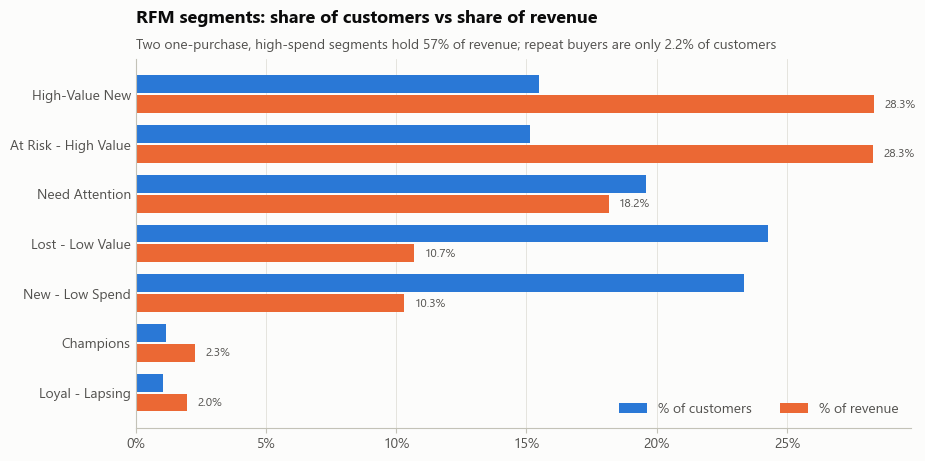

,customers,revenue,avg_recency_days,avg_spend,pct_customers,pct_revenue
segment,,,,,,
High-Value New,14708,"4,458,944.80",97.50,303.20,15.50,28.30
At Risk - High Value,14361,"4,453,787.40",400.60,310.10,15.10,28.30
Need Attention,18610,"2,856,305.10",226.10,153.50,19.60,18.20
Lost - Low Value,23041,"1,680,142.40",402.60,72.90,24.30,10.70
New - Low Spend,22198,"1,623,125.40",95.90,73.10,23.40,10.30
Champions,1088,"355,540.90",92.50,326.80,1.10,2.30
Loyal - Lapsing,977,"307,681.10",314.60,314.90,1.00,2.00


In [11]:
seg = (rfm.groupby("segment")
          .agg(customers=("customer_unique_id", "count"), revenue=("monetary", "sum"),
               avg_recency_days=("recency_days", "mean"), avg_spend=("monetary", "mean"))
          .sort_values("revenue"))
seg["pct_customers"] = seg.customers / seg.customers.sum() * 100
seg["pct_revenue"] = seg.revenue / seg.revenue.sum() * 100
top_two = seg.pct_revenue.loc[["High-Value New", "At Risk - High Value"]].sum()
repeat_share = seg.pct_customers.loc[["Champions", "Loyal - Lapsing"]].sum()

fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(seg))
h = 0.36
ax.barh(y + h / 2 + 0.02, seg.pct_customers, height=h, color=BLUE, label="% of customers")
ax.barh(y - h / 2 - 0.02, seg.pct_revenue, height=h, color=ORANGE, label="% of revenue")
for yi, v in zip(y, seg.pct_revenue):
    ax.text(v + 0.4, yi - h / 2 - 0.02, f"{v:.1f}%", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, labels=seg.index)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", ncols=2)
ax.set_title("RFM segments: share of customers vs share of revenue", pad=26)
subtitle(ax, f"Two one-purchase, high-spend segments hold {top_two:.0f}% of revenue; repeat buyers are only {repeat_share:.1f}% of customers")
save(fig, "03_rfm_segments")

seg.sort_values("revenue", ascending=False).round(1)

**Segment rules** (`sql/06_rfm_segmentation.sql`): R and M are quintile scores (5 = best). F is the number of purchase days, because quintiles do not work when almost everyone has F = 1.

**Takeaway:** the two segments that matter most both bought **once** and spent a lot:
- **High-Value New** (14.7k customers, avg R$303, bought in the last ~3 months): the best audience for a *second-purchase* campaign right now.
- **At Risk - High Value** (14.4k customers, avg R$310, last order over a year ago): a *win-back* audience. These customers are slipping away.

## 6. Delivery experience and reviews

In [12]:
reviewed = delivered.dropna(subset=["review_score"]).copy()
reviewed["status"] = np.where(reviewed.is_late == 1, "Late", "On time / early")
by_status = reviewed.groupby("status").agg(
    orders=("order_id", "count"),
    avg_review=("review_score", "mean"),
    pct_1_2_star=("review_score", lambda s: (s <= 2).mean() * 100),
    pct_5_star=("review_score", lambda s: (s == 5).mean() * 100),
)
promised = (pd.to_datetime(delivered.estimated_date) - pd.to_datetime(delivered.purchase_date)).dt.days
print(f"late deliveries      : {delivered.is_late.mean():.1%} of delivered orders ({int(delivered.is_late.sum()):,})")
print(f"avg delivery time    : {delivered.delivery_days.mean():.1f} days (promised on average: {promised.mean():.1f} days)")
print(f"spearman correlation : delay_days vs review_score = {reviewed[['delay_days', 'review_score']].corr('spearman').iloc[0, 1]:.2f}")

# Robustness: does the gap hold inside one state? (late orders cluster in far-away states)
sp = reviewed[reviewed.customer_state == "SP"].groupby("status").review_score.mean()
print(f"within Sao Paulo only: late {sp['Late']:.2f} vs on time {sp['On time / early']:.2f}")
by_status

late deliveries      : 6.8% of delivered orders (6,534)
avg delivery time    : 12.6 days (promised on average: 24.4 days)
spearman correlation : delay_days vs review_score = -0.18
within Sao Paulo only: late 2.55 vs on time 4.32


,orders,avg_review,pct_1_2_star,pct_5_star
status,,,,
Late,6381,2.27,62.40,16.55
On time / early,89443,4.29,9.27,62.26


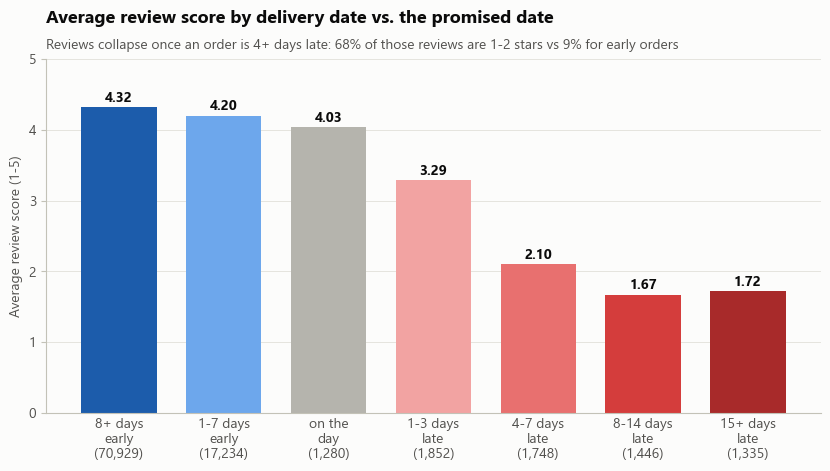

,orders,avg_review,pct_1_2_star
delay_bucket,,,
8+ days early,70929,4.32,8.97
1-7 days early,17234,4.20,10.25
on the day,1280,4.03,12.42
1-3 days late,1852,3.29,32.13
4-7 days late,1748,2.10,67.62
8-14 days late,1446,1.67,80.15
15+ days late,1335,1.72,78.35


In [13]:
bins = [-np.inf, -8, -1, 0, 3, 7, 14, np.inf]
names = ["8+ days\nearly", "1-7 days\nearly", "on the\nday", "1-3 days\nlate", "4-7 days\nlate", "8-14 days\nlate", "15+ days\nlate"]
reviewed["delay_bucket"] = pd.cut(reviewed.delay_days, bins=bins, labels=names)
bucket = reviewed.groupby("delay_bucket", observed=True).agg(
    orders=("order_id", "count"),
    avg_review=("review_score", "mean"),
    pct_1_2_star=("review_score", lambda s: (s <= 2).mean() * 100),
)

# Diverging colours: blue = early, gray = on the day, red = late
colors = ["#1c5cab", "#6da7ec", "#b5b4ad", "#f2a3a2", "#e8706f", "#d43d3c", "#a82a2a"]
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(bucket))
ax.bar(x, bucket.avg_review, width=0.72, color=colors)
for xi, score in zip(x, bucket.avg_review):
    ax.text(xi, score + 0.08, f"{score:.2f}", ha="center", fontsize=10, color=INK, fontweight="bold")
ax.set_xticks(x, labels=[f"{n}\n({c:,})" for n, c in zip(bucket.index, bucket.orders)])
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score (1-5)")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", length=0)
neg_late = bucket.loc["4-7 days\nlate", "pct_1_2_star"]
neg_early = bucket.loc["8+ days\nearly", "pct_1_2_star"]
ax.set_title("Average review score by delivery date vs. the promised date", pad=26)
subtitle(ax, f"Reviews collapse once an order is 4+ days late: {neg_late:.0f}% of those reviews are 1-2 stars vs {neg_early:.0f}% for early orders")
save(fig, "04_review_by_delay")

bucket.rename(index=lambda s: s.replace("\n", " ")).round(2)

correlation between monthly late rate and monthly avg review: -0.92


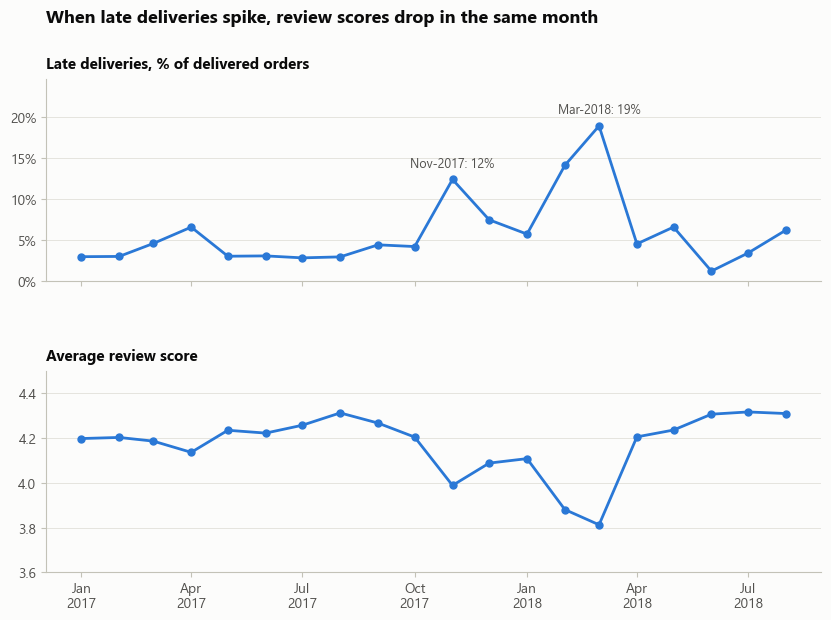

In [14]:
mon = (delivered[delivered.purchase_month.between(TREND_START, TREND_END)]
       .groupby("purchase_month")
       .agg(late_pct=("is_late", lambda s: s.mean() * 100), avg_review=("review_score", "mean"))
       .reset_index())
mon["month"] = pd.to_datetime(mon.purchase_month + "-01")
print(f"correlation between monthly late rate and monthly avg review: {mon.late_pct.corr(mon.avg_review):.2f}")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={"hspace": 0.45})
a1.plot(mon.month, mon.late_pct, color=BLUE, marker="o", markersize=5)
a1.set_ylim(0, mon.late_pct.max() * 1.3)
a1.yaxis.set_major_formatter(PercentFormatter(decimals=0))
a1.set_title("Late deliveries, % of delivered orders", fontsize=11, pad=8)
for _, row in mon[mon.purchase_month.isin(["2017-11", "2018-03"])].iterrows():
    a1.annotate(f"{row.month:%b-%Y}: {row.late_pct:.0f}%", xy=(row.month, row.late_pct), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9, color=INK2)
a2.plot(mon.month, mon.avg_review, color=BLUE, marker="o", markersize=5)
a2.set_ylim(3.6, 4.5)
a2.set_title("Average review score", fontsize=11, pad=8)
for a in (a1, a2):
    a.grid(axis="x", visible=False)
a2.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
a2.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.suptitle("When late deliveries spike, review scores drop in the same month", x=0.125, ha="left",
             fontsize=13, fontweight="bold", color=INK, y=0.99)
save(fig, "05_late_rate_and_reviews_by_month")

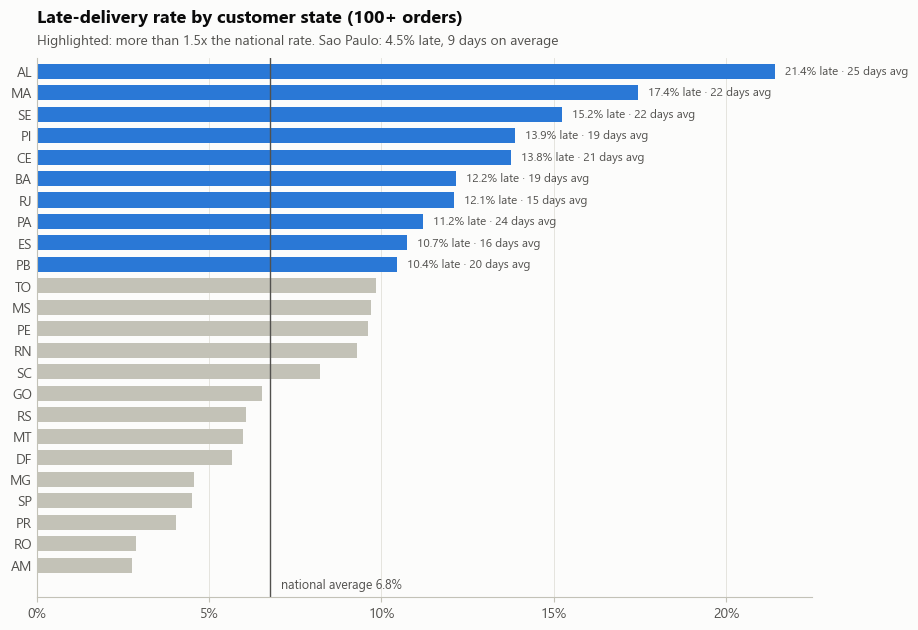

In [15]:
st = delivered.groupby("customer_state").agg(
    orders=("order_id", "count"),
    late_pct=("is_late", lambda s: s.mean() * 100),
    avg_days=("delivery_days", "mean"),
)
st = st[st.orders >= 100].sort_values("late_pct")
national = delivered.is_late.mean() * 100
highlight = st.late_pct > national * 1.5

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(st.index, st.late_pct, height=0.7, color=np.where(highlight, BLUE, GRAY))
ax.axvline(national, color=INK2, lw=1)
ax.text(national + 0.3, -0.9, f"national average {national:.1f}%", color=INK2, fontsize=9, va="center")
for i, (v, d, hl) in enumerate(zip(st.late_pct, st.avg_days, highlight)):
    if hl:
        ax.text(v + 0.3, i, f"{v:.1f}% late · {d:.0f} days avg", va="center", fontsize=8.5, color=INK2)
ax.set_ylim(-1.5, len(st) - 0.4)
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("Late-delivery rate by customer state (100+ orders)", pad=26)
subtitle(ax, f"Highlighted: more than 1.5x the national rate. Sao Paulo: {st.loc['SP', 'late_pct']:.1f}% late, {st.loc['SP', 'avg_days']:.0f} days on average")
save(fig, "06_late_rate_by_state")

repeat rate | first order on time: 2.93% (n=51,560)  late: 1.99% (n=3,667)
relative drop: 32% | two-proportion z = 3.29, p-value = 0.0010


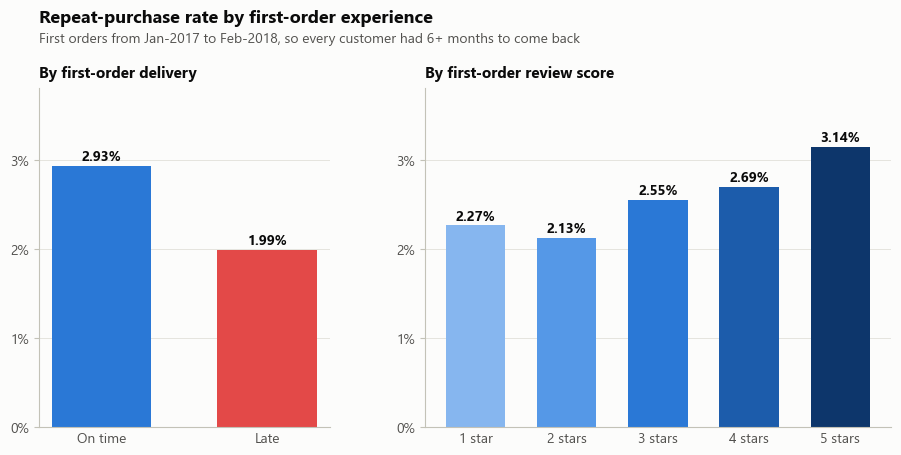

,customers,repeat_rate_pct
first_order_review,,
1,6176,2.27
2,1834,2.13
3,4864,2.55
4,11095,2.69
5,31909,3.14


In [16]:
# Does a bad first experience stop customers from coming back?
# First purchases Jan-2017 .. Feb-2018 only, so everyone had 6+ months to return.
first = (orders.sort_values(["purchase_ts", "order_id"])
               .groupby("customer_unique_id").head(1)
               .merge(customers[["customer_unique_id", "n_purchase_days"]], on="customer_unique_id"))
first = first[first.purchase_month.between("2017-01", "2018-02")]
first["came_back"] = first.n_purchase_days >= 2

fd = first[first.is_delivered == 1]
on_time, late = fd[fd.is_late == 0].came_back, fd[fd.is_late == 1].came_back
p_on, p_late, z, p_value = two_prop_ztest(on_time.sum(), len(on_time), late.sum(), len(late))
print(f"repeat rate | first order on time: {p_on:.2%} (n={len(on_time):,})  late: {p_late:.2%} (n={len(late):,})")
print(f"relative drop: {1 - p_late / p_on:.0%} | two-proportion z = {z:.2f}, p-value = {p_value:.4f}")

by_review = first.dropna(subset=["review_score"]).groupby("review_score").came_back.agg(["size", "mean"])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.6], "wspace": 0.25})
a1.bar(["On time", "Late"], [p_on * 100, p_late * 100], color=[BLUE, RED], width=0.6)
for xi, v in enumerate([p_on * 100, p_late * 100]):
    a1.text(xi, v + 0.06, f"{v:.2f}%", ha="center", fontsize=10, color=INK, fontweight="bold")
a1.set_title("By first-order delivery", fontsize=11, pad=8)
ramp = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
a2.bar([f"{int(s)} star{'s' if s > 1 else ''}" for s in by_review.index], by_review["mean"] * 100, color=ramp, width=0.65)
for xi, v in enumerate(by_review["mean"] * 100):
    a2.text(xi, v + 0.06, f"{v:.2f}%", ha="center", fontsize=10, color=INK, fontweight="bold")
a2.set_title("By first-order review score", fontsize=11, pad=8)
for a in (a1, a2):
    a.set_ylim(0, 3.8)
    a.yaxis.set_major_locator(MultipleLocator(1))
    a.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    a.grid(axis="x", visible=False)
    a.tick_params(axis="x", length=0)
fig.suptitle("Repeat-purchase rate by first-order experience", x=0.125, ha="left",
             fontsize=13, fontweight="bold", color=INK, y=1.06)
fig.text(0.125, 0.985, "First orders from Jan-2017 to Feb-2018, so every customer had 6+ months to come back",
         ha="left", fontsize=10, color=INK2)
save(fig, "07_repeat_rate_by_first_experience")

by_review.index = by_review.index.astype(int).rename("first_order_review")
by_review.assign(repeat_rate_pct=by_review["mean"] * 100).drop(columns="mean").rename(columns={"size": "customers"})

**Robustness check.** The test above asks whether a customer *ever* bought again. Customers from earlier months had longer to come back, and late deliveries were most common in the months with the least follow-up (Nov-2017 and Feb-2018), so that comparison can overstate the effect. `scripts/robustness_check.py` repeats it four more ways: the same 180 days for everyone (**B**), early cohorts only (**C**), inside each first-order month (**D**, Mantel-Haenszel) and with controls for month, state and order value (**E**, logistic regression). It runs as part of `run_pipeline.py`, and this cell reads its saved results.

In [ ]:
# Results of scripts/robustness_check.py (A = the test above; B-E give every customer the same time to come back)
robust = pd.read_csv(ROOT / "outputs" / "robustness" / "first_order_late_vs_repeat.csv")
shown = pd.DataFrame({
    "variant": robust.variant,
    "what changes": robust.description,
    "late": robust.rate_late_pct.map("{:.2f}%".format, na_action="ignore"),
    "on time": robust.rate_on_time_pct.map("{:.2f}%".format, na_action="ignore"),
    "late vs on time": robust.relative_change_pct.map("{:+.0f}%".format, na_action="ignore"),
    "odds ratio": robust.odds_ratio.map("{:.2f}".format, na_action="ignore"),
    "p-value": robust.p_value.map("{:.3f}".format),
}).fillna("")
print(shown.to_string(index=False))

lower = int((robust.relative_change_pct.dropna() < 0).sum() + (robust.odds_ratio.dropna() < 1).sum())
significant = int((robust.p_value < 0.05).sum())
print(f"\nA late first order goes with a lower repeat rate in {lower} of {len(robust)} variants, "
      f"but p < 0.05 in only {significant}.")

variant                                                                      what changes  late on time late vs on time odds ratio p-value
      A                      original: first orders Jan-2017..Feb-2018, ever bought again 1.99%   2.93%            -32%              0.001
      B                        equal window: same customers, bought again within 180 days 1.61%   2.03%            -21%              0.077
      C                   early cohorts: first orders Jan-2017..Oct-2017, within 180 days 1.81%   2.18%            -17%              0.398
      D                stratified by first-order month (Mantel-Haenszel), within 180 days                                     0.81   0.132
      E adjusted for first-order month, state and order value (logistic), within 180 days                                     0.83   0.184

A late first order goes with a lower repeat rate in 5 of 5 variants, but p < 0.05 in only 1.


**Takeaway:** delivery is the biggest driver of customer satisfaction that we can measure here.
- Olist **promises about 24 days but delivers in about 12.6**, so most orders arrive early. Yet **6.8%** still arrive after the promised date.
- Late orders average **2.27 stars vs 4.29**, and **62%** of their reviews are 1-2 stars (vs 9%). The same gap shows up inside São Paulo alone, so it is not just a far-away-state effect.
- Monthly late-rate spikes (**Nov-2017 Black Friday, Feb–Mar 2018**) line up with the lowest review months.
- North-East states such as AL and MA wait **20+ days** and get late orders **3-5x** more often than São Paulo.
- A late **first** order goes with a lower repeat rate: **2.93% → 1.99%** (-32%, p = 0.001) when we ask whether the customer *ever* came back. That comparison favours early cohorts, though. With the same 180 days for everyone the gap is **-21% (p = 0.08)**, and it is not statistically significant once month, state and order value are controlled for. Treat it as **suggestive, not proven**. Delivery is a *hygiene factor* either way: even customers whose first order was on time rarely return (2.9%). Fixing logistics protects ratings. On its own it will not create loyalty.

## 7. Sellers and categories

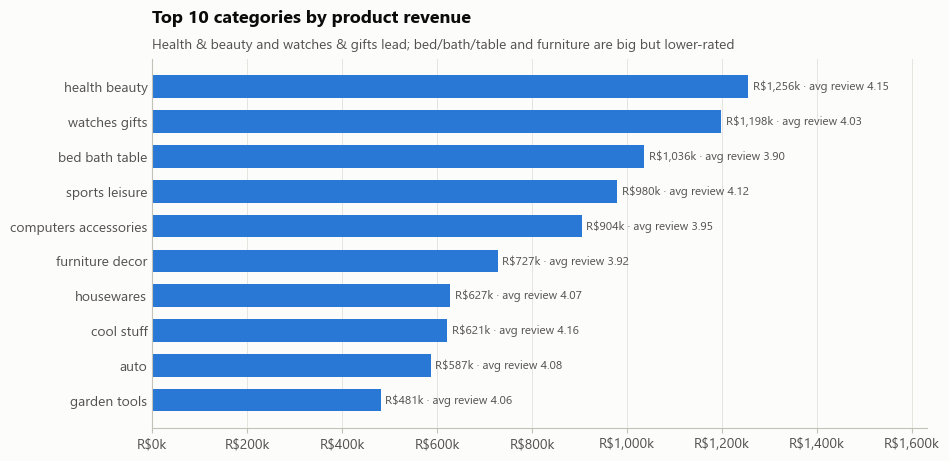

In [17]:
cats = pd.read_csv(SQL_RESULTS / "08_sellers_products__top_categories.csv").head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(cats.category.str.replace("_", " "), cats.product_revenue / 1e3, color=BLUE, height=0.65)
for i, (v, r) in enumerate(zip(cats.product_revenue / 1e3, cats.avg_review_score)):
    ax.text(v + 10, i, f"R${v:,.0f}k · avg review {r:.2f}", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, cats.product_revenue.max() / 1e3 * 1.3)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"R${v:,.0f}k"))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("Top 10 categories by product revenue", pad=26)
subtitle(ax, "Health & beauty and watches & gifts lead; bed/bath/table and furniture are big but lower-rated")
save(fig, "08_top_categories")

In [18]:
conc = pd.read_csv(SQL_RESULTS / "08_sellers_products__seller_revenue_concentration.csv")
late_conc = pd.read_csv(SQL_RESULTS / "08_sellers_products__late_orders_concentration.csv")
print(f"top 10% of sellers bring {conc.pct_revenue.iloc[0]:.1f}% of revenue (top 20%: {conc.cumulative_pct_revenue.iloc[1]:.1f}%)")
print(f"the 30% of sellers with the worst late rate cause {late_conc.pct_of_all_late.head(3).sum():.0f}% of all late orders")

display(pd.read_csv(SQL_RESULTS / "08_sellers_products__lowest_rated_categories.csv").head(5))
pd.read_csv(SQL_RESULTS / "08_sellers_products__seller_scorecard.csv").head(10)   # sellers with 100+ orders, worst late rate first

top 10% of sellers bring 67.5% of revenue (top 20%: 82.6%)
the 30% of sellers with the worst late rate cause 54% of all late orders


,category,orders,avg_review_score,pct_1_2_star,late_pct
0,office_furniture,1262,3.49,26.10,7.90
1,unknown,1425,3.86,21.70,7.50
2,bed_bath_table,9295,3.90,18.80,6.90
3,furniture_decor,6375,3.92,19.00,6.90
4,computers_accessories,6616,3.95,18.10,6.40


,seller_id,seller_state,delivered_orders,revenue,avg_delivery_days,late_pct,avg_review_score
0,06a2c3af7b3aee5d69171b0e14f0ee87,MA,389,"36,409.00",17.70,19.00,4.01
1,88460e8ebdecbfecb5f9601833981930,PR,246,"31,397.00",17.80,17.10,3.43
2,1ca7077d890b907f89be8c954a02686a,SP,108,"13,342.00",15.50,16.70,2.39
3,e5a3438891c0bfdb9394643f95273d8e,SP,216,"7,711.00",15.70,15.70,3.99
4,cd68562d3f44870c08922d380acae552,SP,122,"18,371.00",16.30,15.60,4.02
5,2c9e548be18521d1c43cde1c582c6de8,SP,124,"6,109.00",13.70,15.30,4.13
6,f7ba60f8c3f99e7ee4042fdef03b70c4,SP,218,"68,395.00",13.40,13.80,4.22
7,431af27f296bc6519d890aa5a05fdb11,SP,116,"13,110.00",17.20,13.80,3.80
8,8160255418d5aaa7dbdc9f4c64ebda44,SP,380,"47,018.00",16.20,13.70,3.95
9,b499c00f28f4b7069ff6550af8c1348a,SP,147,"10,327.00",11.30,12.90,4.22


## 8. What-if: sizing the opportunity

In [19]:
uplift = repeaters.total_spend.mean() - one_timers.total_spend.mean()
extra_repeaters = len(customers) * 0.01
print(f"+1 percentage point repeat rate = {extra_repeaters:,.0f} more repeat customers "
      f"x R${uplift:,.0f} extra spend each = about R${extra_repeaters * uplift:,.0f} extra revenue")

late_orders = int(delivered.is_late.sum())
neg_gap = (by_status.loc["Late", "pct_1_2_star"] - by_status.loc["On time / early", "pct_1_2_star"]) / 100
print(f"halving late deliveries ({late_orders / 2:,.0f} orders) would avoid about "
      f"{late_orders / 2 * neg_gap:,.0f} one- and two-star reviews")
equal_window = robust[robust.variant == "B"].iloc[0]       # same 180 days for every customer (section 6)
gap_equal = (equal_window.rate_on_time_pct - equal_window.rate_late_pct) / 100
print(f"...and win back about {late_orders / 2 * (p_on - p_late):,.0f} repeat customers with the original gap, "
      f"or about {late_orders / 2 * gap_equal:,.0f} with the equal-window gap")

+1 percentage point repeat rate = 950 more repeat customers x R$159 extra spend each = about R$150,998 extra revenue
halving late deliveries (3,267 orders) would avoid about 1,736 one- and two-star reviews
...and win back about 31 repeat customers with the original gap, or about 14 with the equal-window gap


**Reading the numbers honestly:** better delivery is mainly a **reputation** win (about 1,700 fewer bad reviews). Its effect on repeat customers is small (about 14 to 31, depending on which gap is used, and possibly zero). The bigger money is in **active retention marketing**: each extra percentage point of repeat rate is worth roughly **R$150k** for a customer base of this size.

## 9. Key insights and recommendations

| # | Insight | Evidence | Recommendation |
|---|---|---|---|
| 1 | **Customers buy once and leave** | 97.8% one-time buyers; <0.5% return the next month | Start a **second-purchase program**: a post-delivery email/voucher on days 7-30, since 55% of repeat purchases happen within 90 days |
| 2 | **Repeat customers are worth 2x** | R$321 vs R$162 lifetime spend | Track **repeat rate** as a core KPI. +1 pp ≈ R$150k revenue |
| 3 | **Two segments hold 57% of revenue** | High-Value New (14.7k) and At Risk - High Value (14.4k) | Target *High-Value New* with recommendations now; run a **win-back** campaign for *At Risk - High Value* |
| 4 | **Late delivery destroys reviews** | 2.27 vs 4.29 stars; 62% negative when late | **Proactive delay alerts** plus a small goodwill voucher when an order is predicted to be late |
| 5 | **Peaks break logistics** | Late rate 12% in Nov-2017 and 19% in Mar-2018 | **Capacity planning** with carriers and sellers before Black Friday and other peaks |
| 6 | **The North-East is underserved** | AL/MA: 20+ days, 17-21% late vs SP 9 days, 4.5% | Regional carriers or fulfilment hubs; **region-specific delivery estimates** |
| 7 | **A few sellers cause most delays** | Worst 30% of sellers = 54% of late orders | **Seller scorecard** with SLA targets; coach or penalise repeat offenders |
| 8 | **Promises are padded** | 24 days promised vs 12.6 actual | **A/B test** shorter, accurate estimates in fast regions (may lift conversion) |

**Limitations:** this is a public sample of Olist data (2016-2018) with no marketing, traffic or cost data. The delivery → repeat link is only suggestive (section 6: the -32% gap shrinks to -21%, p = 0.08, once every customer has the same follow-up time), so recommendations 1-3 should be validated with A/B tests.

In [20]:
conn.close()